[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bihjane/data-science-and-ai-k-12-teaching-tools/blob/main/intelligent-futures-free-courses/colab-notebooks/06_clustering_countries_kmeans.ipynb)

# Finding groups of countries with clustering
**Level:** intermediate · **Time:** 45 minutes · **Model:** k-means clustering (unsupervised learning)

**Question:** Without telling the computer any labels, can it find groups of countries with similar income, health and population?

Data: Gapminder 2007 (142 countries), built into the free `plotly` library.

## How to use this notebook
1. Click **Open in Colab** above, or upload this file at [colab.research.google.com](https://colab.research.google.com) (File > Upload notebook).
2. Run each code cell in order with **Shift + Enter**.
3. Before running a cell, **predict** what it will show. After running it, check your prediction.
4. Try the **Your turn** tasks at the end of each step.

No installs or downloads are needed. Everything runs free in your browser.

## Step 1. Load the data

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import plotly.express as px

df = px.data.gapminder().query("year == 2007").reset_index(drop=True)
df["log_gdp"] = np.log10(df.gdpPercap)
df["log_pop"] = np.log10(df["pop"])
df[["country", "continent", "lifeExp", "log_gdp", "log_pop"]].head()

,country,continent,lifeExp,log_gdp,log_pop
0,Afghanistan,Asia,43.828,2.988818,7.503653
1,Albania,Europe,76.423,3.773569,6.556366
2,Algeria,Africa,72.301,3.794025,7.522877
3,Angola,Africa,42.731,3.680991,7.094138
4,Argentina,Americas,75.320,4.106510,7.605326


## Step 2. Choose and scale the features
k-means measures distance, so features must be on the same scale.

In [2]:
from sklearn.preprocessing import StandardScaler
features = ["lifeExp", "log_gdp", "log_pop"]
Xs = StandardScaler().fit_transform(df[features])
Xs[:3].round(2)

array([[-1.93, -1.28,  0.66],
       [ 0.78,  0.05, -0.78],
       [ 0.44,  0.09,  0.69]])

## Step 3. How many groups? The elbow method

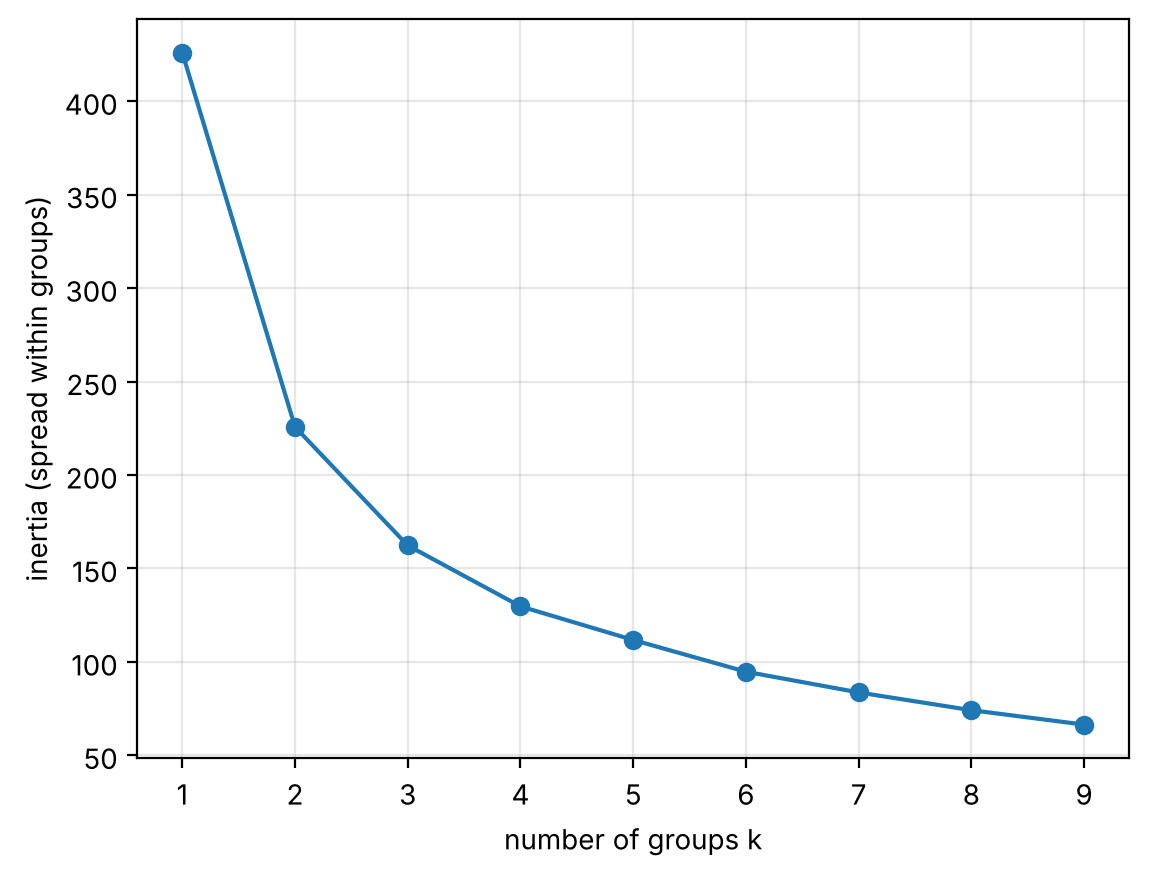

In [3]:
from sklearn.cluster import KMeans
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs).inertia_ for k in range(1, 10)]
plt.plot(range(1, 10), inertia, "o-"); plt.xlabel("number of groups k"); plt.ylabel("inertia (spread within groups)")
plt.grid(alpha=0.3); plt.show()

Pick the k where the curve bends and further drops get small. Here we try **k = 4**.

## Step 4. Find the groups

In [4]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xs)
df["group"] = km.labels_.astype(str)
df.groupby("group")[["lifeExp", "gdpPercap", "pop"]].median().round(0)

,lifeExp,gdpPercap,pop
group,,,
0,73.0,11112.0,59461986.0
1,76.0,14619.0,5675356.0
2,53.0,1091.0,14326203.0
3,55.0,2589.0,1555586.0


## Step 5. See the groups on a map and a chart

In [5]:
px.choropleth(df, locations="iso_alpha", color="group", hover_name="country", title="Country groups found by k-means (2007)").show()
px.scatter(df, x="gdpPercap", y="lifeExp", color="group", log_x=True, hover_name="country").show()

## Step 6. Name and check the groups

In [6]:
for g, sub in df.groupby("group"):
    print(f"Group {g}: {len(sub)} countries, e.g. {', '.join(sub.sort_values('pop', ascending=False).country.head(5))}")

Group 0: 34 countries, e.g. China, India, United States, Indonesia, Brazil
Group 1: 53 countries, e.g. Australia, Netherlands, Chile, Ecuador, Guatemala
Group 2: 41 countries, e.g. Bangladesh, Nigeria, Ethiopia, Congo, Dem. Rep., Myanmar
Group 3: 14 countries, e.g. Congo, Rep., Mauritania, Mongolia, Namibia, Lesotho


**Your turn:** Give each group a short, respectful name based on its median values (for example "high income, long life"). Do the groups match continents? Why or why not?

## Your turn: extensions
1. Add or remove a feature and re-run. Do countries move between groups?
2. Try k = 3 and k = 5.
3. Discuss: what decisions could someone make from these groups, and what could go wrong?

---
*Intelligent Futures · Dr. Janet Bih Shufor · Free for classroom use with attribution.*